# v2.0 流水线测试：20 秒片段

1. 从 `test_data` 截取 **20 秒** timestamp 序列  
2. `rig_pairs`：从 `start_ts` 起 **每秒 1 个 keyframe**，生成 pairs  
3. `feature_pairs`：特征 / 匹配 / INS 三角化 → `sfm/`，并 **3D 可视化地图**  
4. 段内选一帧 **query**：GT、检索 prior、预测位姿，**3D 可视化**（参考 `hloc/demo hloc.ipynb`）

**Kernel：** `SchubKI v2.0`（或解释器 `v2.0/.venv-schubki-v2/bin/python`）· 运行前：`source v2.0/scripts/env.sh`

## 0. 环境与路径

In [1]:
import os
import sys
from pathlib import Path

import numpy as np

TEST_DIR = Path.cwd().resolve()
V2_ROOT = TEST_DIR.parent
sys.path.insert(0, str(V2_ROOT / "src"))

HLOC_ROOT = V2_ROOT / "third_party" / "Hierarchical-Localization"
sys.path.insert(0, str(HLOC_ROOT))
os.environ.setdefault("HLOC_ROOT", str(HLOC_ROOT))
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

torch_hub = V2_ROOT / "model_cache" / "torch_hub"
torch_hub.mkdir(parents=True, exist_ok=True)
import torch
torch.hub.set_dir(str(torch_hub))

from robotcar.paths import DEFAULT_LEFT_IMAGES, DEFAULT_RIGHT_IMAGES
from robotcar.stereo import sync_stereo_pairs

OUTPUT_DIR = V2_ROOT / "test" / "outputs" / "segment_20s_rig"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("OUTPUT:", OUTPUT_DIR)

OUTPUT: /Users/hbai/SchubKI/v2.0/test/outputs/segment_20s_rig


## 1. 截取 20 秒 ts 序列

In [2]:
SEGMENT_DURATION_US = 20_000_000  # 20 s
KEYFRAME_INTERVAL_US = 1_000_000  # 每秒 1 个 keyframe

synced = sync_stereo_pairs(DEFAULT_LEFT_IMAGES, DEFAULT_RIGHT_IMAGES)
all_ts = [p[0] for p in synced]
print(f"全序列: {len(all_ts)} 帧, 时长 {(all_ts[-1]-all_ts[0])/1e6:.1f} s")

START_TS = all_ts[0]  # 可改为其它 start_ts
END_TS = START_TS + SEGMENT_DURATION_US
segment_ts = [t for t in all_ts if START_TS <= t < END_TS]
print(f"片段: start={START_TS}, end≈{END_TS}, 帧数={len(segment_ts)}, 时长≈{(segment_ts[-1]-segment_ts[0])/1e6:.1f} s")
print("首/末 ts:", segment_ts[0], segment_ts[-1])

全序列: 2929 帧, 时长 192.0 s
片段: start=1400075224469383, end≈1400075244469383, 帧数=311, 时长≈19.9 s
首/末 ts: 1400075224469383 1400075244404040


## 2. `rig_pairs`：每秒 keyframe + pairs

In [3]:
from rig_pairs import KeyframeConfig, PairsConfig, generate_pairs_for_test_data

kf_cfg = KeyframeConfig(
    start_ts=START_TS,
    segment_duration_us=SEGMENT_DURATION_US,
    keyframe_interval_us=KEYFRAME_INTERVAL_US,
)
pc_cfg = PairsConfig(
    max_temporal_gap=5,
    min_baseline_m=0.75,
    include_cross_camera=False,
)
keyframes, pair_lists, pair_paths = generate_pairs_for_test_data(
    output_dir=OUTPUT_DIR,
    keyframe_config=kf_cfg,
    pairs_config=pc_cfg,
)
print(f"Keyframes: {len(keyframes)}, pairs-all: {len(pair_lists.all_pairs)}")
for k in keyframes[:3]:
    print(f"  [{k.index}] ts={k.ts}")
print("  ...")
print(f"  [{keyframes[-1].index}] ts={keyframes[-1].ts}")

Keyframes: 19, pairs-all: 159
  [0] ts=1400075224469383
  [1] ts=1400075225531740
  [2] ts=1400075226594096
  ...
  [18] ts=1400075243591648


## 3. `feature_pairs` → SfM

约 20 keyframes × 2 目：DISK + LightGlue + 三角化。**Apple Silicon** 会自动用 **MPS**（见下方 `inference_device()`）；无 GPU 时纯 CPU 很慢。已跑一半可设 `overwrite_features=False` 续跑。

In [4]:
from hloc.utils.device import inference_device
from feature_pairs import FeaturePairsConfig, FeaturePairsPaths, run_feature_pairs_pipeline

print("DISK / LightGlue device:", inference_device())  # Apple Silicon: mps

fp_cfg = FeaturePairsConfig(
    paths=FeaturePairsPaths(rig_sfm_dir=OUTPUT_DIR),
    overwrite_features=True,
    build_reference=True,
    run_triangulation=True,
)
fp_result = run_feature_pairs_pipeline(fp_cfg)
print(fp_result.graph)
if fp_result.validation:
    print("points3D:", fp_result.validation.num_points3D)
    print("mean reproj:", fp_result.validation.mean_reprojection_error)
model = fp_result.model
assert model is not None

[2026/10/14 23:31:00 hloc INFO] Extracting local features with configuration:
{'model': {'max_keypoints': 5000, 'name': 'disk'},
 'output': 'feats-disk',
 'preprocessing': {'grayscale': False, 'resize_max': 1600}}


DISK / LightGlue device: mps


/Users/hbai/SchubKI/v2.0/.venv-schubki-v2/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
100%|██████████| 38/38 [00:17<00:00,  2.12it/s]
[2026/10/14 23:31:18 hloc INFO] Finished exporting features.
[2026/10/14 23:31:18 hloc INFO] Matching local features with configuration:
{'model': {'features': 'disk', 'name': 'lightglue'},
 'output': 'matches-disk-lightglue'}
100%|██████████| 159/159 [01:49<00:00,  1.46it/s]
[2026/10/14 23:33:08 hloc INFO] Finished exporting matches.
[2026/10/14 23:33:08 hloc WARNING] The database already exists, deleting it.
[2026/10/14 23:33:08 hloc INFO] Importing features into the database...
100%|██████████| 38/38 [00:00<00:00, 2162.51it/s]
[2026/10/14 23:33:08 hloc INFO] Importing matches into the database...
100%|██████████| 159/159 [00:00<00:00, 1501.98it/s]
[2026/10/14 23:33:09 hloc INFO] Performing geometric verification of the matc

KeyframeGraphSummary(num_keyframes=19, num_images=38, num_pairs=159, num_stereo_pairs=19, num_temporal_pairs=140, image_names=['left/1400075224469383.png', 'left/1400075225531740.png', 'left/1400075226594096.png', 'left/1400075227656425.png', 'left/1400075228718755.png', 'left/1400075229781087.png', 'left/1400075230843416.png', 'left/1400075231905828.png', 'left/1400075232968183.png', 'left/1400075234030574.png', 'left/1400075235092934.png', 'left/1400075236155266.png', 'left/1400075237217596.png', 'left/1400075238279926.png', 'left/1400075239342257.png', 'left/1400075240404585.png', 'left/1400075241466938.png', 'left/1400075242529297.png', 'left/1400075243591648.png', 'right/1400075224469383.png', 'right/1400075225531740.png', 'right/1400075226594096.png', 'right/1400075227656425.png', 'right/1400075228718755.png', 'right/1400075229781087.png', 'right/1400075230843416.png', 'right/1400075231905828.png', 'right/1400075232968183.png', 'right/1400075234030574.png', 'right/140007523509293

## 3b. 三维可视化稀疏地图（demo `plot_reconstruction`）

In [5]:
from hloc.utils import viz_3d

fig_map = viz_3d.init_figure()
viz_3d.plot_reconstruction(
    fig_map, model, color="rgba(255,0,0,0.45)", name="mapping", points_rgb=True
)
fig_map.show()

## 4. Query（NetVLAD prior → top-k 局部匹配 → PnP）

需 **`global_features.h5`**（§3 `feature_pairs` 默认会建）。每 query 仅 **LightGlue × retrieval_top_k** 对，不再对全库 exhaustive。

In [6]:
from query import QueryConfig, QueryImageSpec, QueryWorkspacePaths, run_query_localization

keyframe_ts_set = {kf.ts for kf in keyframes}
candidates = [t for t in segment_ts if t not in keyframe_ts_set]
QUERY_TS = candidates[len(candidates) // 3] if candidates else segment_ts[len(segment_ts) // 2]
QUERY_CAMERA = "left"
print(f"Query ts={QUERY_TS}, camera={QUERY_CAMERA}")

q_result = run_query_localization(
    QueryImageSpec(timestamp_us=QUERY_TS, camera=QUERY_CAMERA),
    QueryConfig(
        paths=QueryWorkspacePaths(rig_sfm_dir=OUTPUT_DIR),
        retrieval_top_k=5,
    ),
)
print("GT:", q_result.gt_cam_from_world.summary())
print("Retrieval (match count):")
for r in q_result.retrieval:
    print(f"  {r.image_name}: {r.match_count}")
if q_result.predicted.success:
    print("Predicted:", q_result.predicted.cam_from_world.summary())
    print(f"Inliers: {q_result.predicted.num_inliers}/{q_result.predicted.num_correspondences}")
else:
    print("Predicted: FAILED")

[2026/10/14 23:34:26 hloc INFO] Extracting local features with configuration:
{'model': {'max_keypoints': 5000, 'name': 'disk'},
 'output': 'feats-disk',
 'preprocessing': {'grayscale': False, 'resize_max': 1600}}


Query ts=1400075230968397, camera=left


100%|██████████| 1/1 [00:01<00:00,  1.22s/it]
[2026/10/14 23:34:27 hloc INFO] Finished exporting features.
[2026/10/14 23:34:27 hloc INFO] Found 38 pairs.
[2026/10/14 23:34:27 hloc INFO] Matching local features with configuration:
{'model': {'features': 'disk', 'name': 'lightglue'},
 'output': 'matches-disk-lightglue'}
100%|██████████| 38/38 [00:25<00:00,  1.48it/s]
[2026/10/14 23:34:53 hloc INFO] Finished exporting matches.


GT: Rigid3d:
    params = [ ... 7 elements ... ]
    rotation: Rotation3d:
        quat = [ 0.47719251  0.50443531  0.53895735 -0.47681998]
    translation = [ 0.51382127  1.21241414 -5.56153278]
Retrieval (match count):
  left/1400075230843416.png: 4005
  right/1400075230843416.png: 3812
  right/1400075229781087.png: 2798
  left/1400075229781087.png: 2722
  right/1400075228718755.png: 2490
Predicted: Rigid3d:
    params = [ ... 7 elements ... ]
    rotation: Rotation3d:
        quat = [ 0.47822443  0.51264778  0.53911807 -0.46673906]
    translation = [ 0.64064241  1.18819107 -5.54776638]
Inliers: 896/1514


## 4b. Query 三维：GT vs 预测位姿

In [10]:
from hloc.utils import viz_3d

ret = q_result.pnp_ret


def _print_cam_from_world(label: str, pose) -> None:
    t = np.asarray(pose.translation)
    q = np.asarray(pose.rotation.quat)
    print(f"{label}  (COLMAP cam_from_world, 世界系同 reference/sfm)")
    print(f"  translation [m]:  [{t[0]:+.4f}, {t[1]:+.4f}, {t[2]:+.4f}]")
    print(f"  quaternion wxyz:  [{q[0]:+.6f}, {q[1]:+.6f}, {q[2]:+.6f}, {q[3]:+.6f}]")
    print(pose.summary())
    print()


_print_cam_from_world("GT (query)", q_result.gt_cam_from_world)
if q_result.predicted.cam_from_world is not None:
    _print_cam_from_world("Predicted (query)", q_result.predicted.cam_from_world)
    gt_t = np.asarray(q_result.gt_cam_from_world.translation)
    pr_t = np.asarray(q_result.predicted.cam_from_world.translation)
    print(f"Position error (pred vs GT): {np.linalg.norm(pr_t - gt_t):.4f} m")
    print(
        f"PnP inliers: {q_result.predicted.num_inliers}/"
        f"{q_result.predicted.num_correspondences}"
    )
else:
    print("Predicted (query): PnP failed\n")

fig_q = viz_3d.init_figure()
viz_3d.plot_reconstruction(
    fig_q, model, color="rgba(200,200,200,0.2)", name="map", points_rgb=True, cameras=False
)

viz_3d.plot_camera_colmap(
    fig_q, q_result.gt_cam_from_world, q_result.gt_camera,
    color="rgba(0,100,255,0.65)", name="GT (query)", fill=True,
)

if q_result.predicted.cam_from_world is not None:
    pred_cam = q_result.gt_camera
    if ret and ret.get("camera") is not None:
        pred_cam = ret["camera"]
    viz_3d.plot_camera_colmap(
        fig_q, q_result.predicted.cam_from_world, pred_cam,
        color="rgba(0,220,0,0.65)", name="predicted (query)", fill=True,
    )
else:
    print("Predicted pose unavailable (PnP failed)")

fig_q.show()

GT (query)  (COLMAP cam_from_world, 世界系同 reference/sfm)
  translation [m]:  [+0.5138, +1.2124, -5.5615]
  quaternion wxyz:  [+0.477193, +0.504435, +0.538957, -0.476820]
Rigid3d:
    params = [ ... 7 elements ... ]
    rotation: Rotation3d:
        quat = [ 0.47719251  0.50443531  0.53895735 -0.47681998]
    translation = [ 0.51382127  1.21241414 -5.56153278]

Predicted (query)  (COLMAP cam_from_world, 世界系同 reference/sfm)
  translation [m]:  [+0.6493, +1.1739, -5.5056]
  quaternion wxyz:  [+0.478247, +0.512809, +0.539071, -0.466594]
Rigid3d:
    params = [ ... 7 elements ... ]
    rotation: Rotation3d:
        quat = [ 0.47824656  0.5128092   0.5390705  -0.46659398]
    translation = [ 0.64932763  1.17386121 -5.50557073]

Position error (pred vs GT): 0.1516 m
PnP inliers: 728/1417


## 4c. Query 二维匹配（demo `visualize_loc_from_log`）

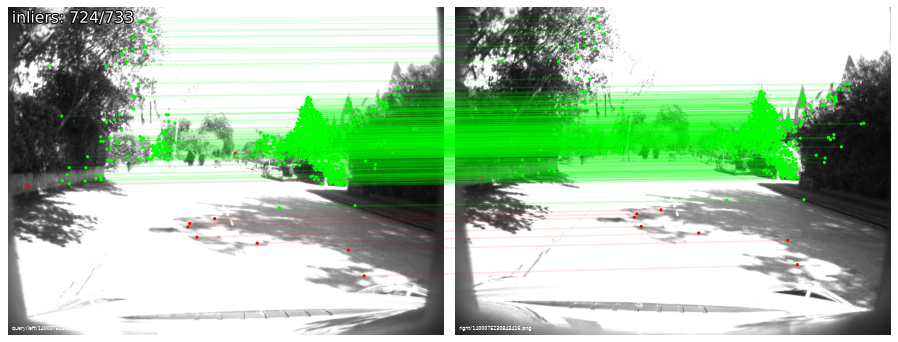

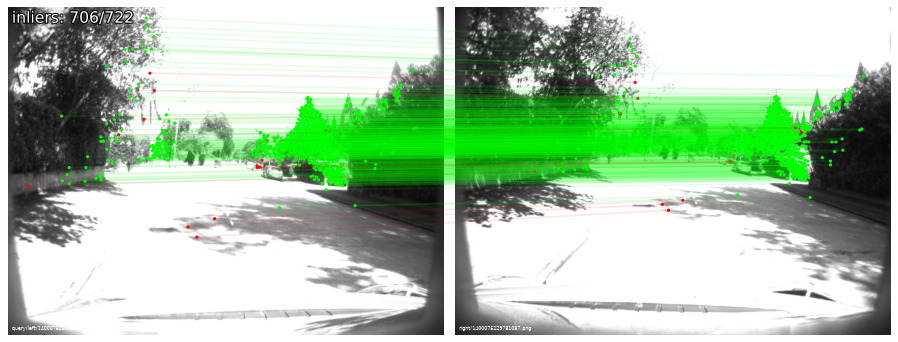

In [8]:
from hloc import visualization

loc = dict(q_result.predicted.log)
loc["PnP_ret"] = q_result.pnp_ret
visualization.visualize_loc_from_log(
    OUTPUT_DIR / "images", q_result.query_name, loc, model, top_k_db=2
)